# Online Retail II: Churn için Özellik Mühendisliği (baştan sona)

Bu notebook, derste birlikte ilerleyeceğimiz **Online Retail churn case'inin** tam akışıdır. Akış, dokümandaki beş adımı takip eder:

| Adım | Ne yapıyoruz? | Bölüm |
|---|---|---|
| 1 | Özellik fikirlerini ve hipotezleri konuşuruz | Bölüm 1 |
| 2 | Veride temel kontroller: sütun tipleri, eksik ve aykırı değerler | Bölüm 2 |
| 3 | Seçtiğimiz fikirleri birlikte kodlarız | Bölüm 3 |
| 4 | Kategorik sütunları sayıya çeviririz (encoding), gerekirse sayısal sütunları aynı ölçeğe getiririz (scaling) | Bölüm 4 |
| 5 | Üretilen özelliklerin Churn ile ilişkisine bakıp hangisinin işe yaradığını konuşuruz | Bölüm 5 |

**Bu notebook'un Telco case'inden farkı:** Telco'da tablo zaten "bir satır = bir müşteri" idi ve özellikler hazır sütunlardı. Burada elimizde **fatura satırları** var (bir satır = bir faturadaki bir ürün). Model ise **müşteri** tahmin eder. Yani her özelliği önce **fatura satırlarını müşteri başına özetleyerek** biz üretiyoruz (`groupby`). Özellik mühendisliği burada işin kendisi: ham tabloyla model kurmak mümkün bile değil.

**Her özellik için aynı üç soru:**

1. **Nasıl hesaplanır?** (kod)
2. **Neden Churn'ü etkileyebilir?** (hipotez, kodu yazmadan önceki tahminimiz)
3. **Nasıl test ederiz?** (gruplara göre churn oranına bakarız)

Kod İngilizce, açıklamalar Türkçe. Kod içindeki yorumlar her sonucun ne anlama geldiğini söyler. Temizliğin ayrıntıları `02_cleaning_and_feature_engineering.ipynb` içinde; burada churn için gereken kadarını yapıyoruz.

> **Çalıştırmak için:** `datasets` klasöründe iki dosya olmalı: `online_retail_II_2009-2010.csv` ve `online_retail_II_2010-2011.csv`. Gerekli kütüphaneler: `pandas`, `numpy`, `matplotlib`, `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Simple, clean chart style used in the whole notebook
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
COLOR_HIGH = "#d95f02"   # bar is above the overall churn rate (riskier group)
COLOR_LOW = "#7a8ea6"    # bar is at or below the overall churn rate
COLOR_NEW = "#0f766e"    # (importance charts) bar is a feature we created
COLOR_RAW = "#b5bdc9"    # (importance charts) bar is a basic RFM column

## Adım 1. Problem, hedef ve özellik fikri nasıl düşünülür?

### Problem

İngiltere merkezli bir online hediyelik eşya satıcısı var. Müşterilerinin çoğu **toptancı**: dükkânlar, küçük işletmeler. Şirket şunu bilmek istiyor: **Hangi müşteri bir daha alışveriş yapmayacak?** Böylece o müşteriye ayrılmadan önce ulaşabilir (kampanya, arama, özel fiyat).

### Hedef (target): "sonraki 90 günde alışveriş yapacak mı?"

Telco'da müşteri sözleşmeyi bozunca ayrılmış sayılıyordu. Burada **sözleşme yok**: müşteri sessizce gelmeyi bırakır. O yüzden ayrılmayı biz **tanımlıyoruz:**

> Bir müşteri, belirlediğimiz bir tarihten sonraki **90 gün içinde hiç alışveriş yapmadıysa** `churn = 1`, yaptıysa `churn = 0`.

Bu tarihe **`cutoff`** (kesit tarihi) diyoruz. Zamanda geriye gidip orada duruyormuş gibi davranıyoruz:

- **`cutoff` öncesi:** müşterinin geçmişi. **Özellikleri** buradan üretiyoruz.
- **`cutoff` sonrası 90 gün:** "gelecek". Sadece **hedefi** bulmak için bakıyoruz.

Neden böyle? Bugünün müşterileri için cevabı henüz bilmiyoruz; modelin tahmin etmesini istiyoruz. Modeli geçmişte cevabı bildiğimiz bir andan eğitip bugüne uygularız.

> **Büyük uyarı (sızıntı, leakage):** Özellik hesaplarken `cutoff` sonrasına ait **tek bir satır** bile kullanırsak model geleceği görmüş olur ve gerçek hayatta çalışmaz. Bölüm 5'te bunun nasıl sahte bir başarı yarattığını göstereceğiz.

### Özellik mühendisliği burada ne demek?

Elimizde `Invoice`, `StockCode`, `Quantity`, `InvoiceDate`, `Price`, `Customer ID`, `Country` gibi **fatura satırı** sütunları var. Bunlar müşteriyi doğrudan anlatmıyor. **Özellik = bir müşterinin satırlarını özetleyen bir sayı.** Mesela:

- son alışverişinden bu yana kaç gün geçti? (`recency`)
- kaç sipariş verdi? (`frequency`)
- siparişleri arasında normalde kaç gün bekliyor, şimdi bunu aştı mı?

### Bir özellik fikri nasıl düşünülür?

Her fikir için üç soru: **nasıl hesaplanır / neden etkiler / nasıl test ederiz.** Fikir bulmak için müşteriye **yedi açıdan** bakabiliriz:

| Açı | Soru |
|---|---|
| **Tazelik** | Müşteri en son ne zaman geldi? |
| **Sıklık ve ritim** | Ne sıklıkla alışveriş yapıyor? Kendi ritmine göre geç mi kaldı? Hızlanıyor mu, yavaşlıyor mu? |
| **Harcama** | Ne kadar harcıyor? Sipariş başına ne kadar? |
| **Ürün çeşitliliği** | Kaç farklı ürün alıyor? Sipariş başına kaç adet? |
| **İade** | Ürünleri iade ediyor mu? |
| **Zaman ve mevsim** | Ne zamandan beri müşteri? Geçen yıl bu dönemde alışveriş yapmış mı? |
| **Müşteri profili** | Hangi ülkeden? |

### Sınıfta: arkadaşların fikirleri

Derste birkaç kişi kendi fikrini anlatır, hipotezi birlikte tartışırız. Aşağıdaki tabloya yazabiliriz:

| Fikir | Nasıl hesaplanır? | Neden Churn'ü etkiler? | Nasıl test ederiz? |
|---|---|---|---|
| | | | |
| | | | |
| | | | |

Bu notebook'ta aşağıda **20 özellik** üreteceğiz. Arkadaşların fikirleri bunların içinde yoksa, Bölüm 3'ün sonunda onları da canlı olarak kodlarız.

## Adım 2. Veride temel kontroller

Özellik üretmeden önce veriyi tanıyoruz. Bu bölümde sırayla:

1. Veriyi okumak ve ilk sorunlar: sütun tipleri, ondalık ayracı, tarih formatı
2. Sütun tipleri (`dtypes`)
3. Eksik değerler
4. Tekrar eden satırlar
5. Satır türleri: satış, iade, ürün olmayan kalemler
6. Aykırı değerler
7. Hedef sütun: `cutoff` ve churn oranı

### 2.1 Veriyi okumak

Veri iki dosyaya bölünmüş (Aralık 2009 - Aralık 2010 ve Aralık 2010 - Aralık 2011). İkisi de aynı şirketin aynı tablosu, yani alt alta birleştirebiliriz. Ama önce **hiçbir ayar yapmadan**, düz `pd.read_csv` ile okuyalım ve ne geldiğine bakalım.

> Not: pandas'ın eski sürümlerinde burada `DtypeWarning: ... mixed types` uyarısı çıkabilir. Bazı sütunlarda hem sayı hem harfli değerler var (ör. `85123A`). Aşağıda bu sütunları baştan yazı olarak okuyarak çözeceğiz.

In [2]:
# Read both files the simplest way: no options at all
part1 = pd.read_csv("datasets/online_retail_II_2009-2010.csv")
part2 = pd.read_csv("datasets/online_retail_II_2010-2011.csv")

print("File 1 (2009-2010):", part1.shape)
print("File 2 (2010-2011):", part2.shape)

File 1 (2009-2010): (525461, 8)
File 2 (2010-2011): (541910, 8)


#### 2.1.1 Önce sütun tiplerine bakalım (`dtypes`)

İki dosyayı alt alta birleştireceğimiz için aynı sütunlar **aynı tipte** olmalı. Yan yana koyup karşılaştıralım.

In [3]:
# Put the column types of both files side by side. "str" (or "object" in older pandas) means TEXT
pd.DataFrame({"file 1 (2009-2010)": part1.dtypes, "file 2 (2010-2011)": part2.dtypes})

,file 1 (2009-2010),file 2 (2010-2011)
Invoice,str,str
StockCode,str,str
Description,str,str
Quantity,int64,int64
InvoiceDate,str,str
Price,str,float64
Customer ID,float64,float64
Country,str,str


**Gözlem:** İki tuhaflık var:

- `Price` 1. dosyada **yazı** (`str`), 2. dosyada **sayı** (`float64`). Aynı sütun, iki farklı tip.
- `InvoiceDate` iki dosyada da **yazı**. Yani henüz tarih değil, tarih gibi görünen bir metin.

(`Customer ID`'nin `float64` olmasına 2.2'de döneceğiz.) Önce fiyata bakalım: neden yazı?

#### 2.1.2 Fiyat neden yazı?

In [4]:
# Look at the first prices of each file
print("File 1:", part1["Price"].head(3).tolist())
print("File 2:", part2["Price"].head(3).tolist())

File 1: ['6,95', '6,75', '6,75']
File 2: [2.55, 3.39, 2.75]


1. dosyada fiyatlar `6,95` diye yazılmış: **ondalık ayracı virgül**. pandas varsayılan olarak ondalık ayracının nokta olduğunu varsayar. Virgüllü metni sayıya çeviremez ve sütunu yazı olarak bırakır. Zorla sayıya çevirmeyi deneyelim:

In [5]:
# Try to force the conversion: it fails because of the comma
try:
    part1["Price"].astype(float)
except ValueError as error:
    print("Error:", error)

Error: could not convert string to float: '6,95'


Çözüm: `read_csv`'ye bu dosyada ondalık ayracının virgül olduğunu söylemek: `decimal=","`.

#### 2.1.3 Tarih nasıl yazılmış?

In [6]:
# Look at the first dates of each file
print("File 1:", part1["InvoiceDate"].head(3).tolist())
print("File 2:", part2["InvoiceDate"].head(3).tolist())

File 1: ['12/1/09 7:45', '12/1/09 7:45', '12/1/09 7:45']
File 2: ['2010-12-01 08:26:00', '2010-12-01 08:26:00', '2010-12-01 08:26:00']


Tarihler de **farklı formatta**: 1. dosya `12/1/09 7:45`, 2. dosya `2010-12-01 08:26:00`.

- 2. dosya standart (yıl-ay-gün-saat) olduğu için pandas kendisi anlar (`parse_dates`).
- 1. dosya **belirsiz**: `12/1/09` 12 Ocak mı, 1 Aralık mı? Veriyi tanıyarak karar veriyoruz. Önce "gün/ay/yıl" deneyelim. Dosya aslında "ay/gün/yıl" ise, `12/13/09` gibi bir değeri "gün/ay/yıl" diye okumaya çalışınca ay 13 çıkar ve hata alırız.

In [7]:
# Try DAY first (%d/%m/%y). It should fail if the file is really month-first
try:
    pd.to_datetime(part1["InvoiceDate"], format="%d/%m/%y %H:%M")
except ValueError as error:
    print("Day-first failed:", str(error).split(". ")[0])

# Now try MONTH first (%m/%d/%y)
dates = pd.to_datetime(part1["InvoiceDate"], format="%m/%d/%y %H:%M")
print("Month-first worked. Date range:", dates.min(), "->", dates.max())

Day-first failed: time data "12/13/09 9:58" doesn't match format "%d/%m/%y %H:%M"
Month-first worked. Date range: 2009-12-01 07:45:00 -> 2010-12-09 20:01:00


Gün/ay/yıl hata verdi (`12/13/09` içindeki 13 ay olamaz), ay/gün/yıl çalıştı. Kontrol: tarih aralığı 1 Aralık 2009'da başlıyor ve 2010 sonunda bitiyor, dosya adıyla uyuyor.

#### 2.1.4 İki dosyayı doğru ayarlarla okuyup birleştirelim

| | 2009-2010 dosyası | 2010-2011 dosyası |
|---|---|---|
| Ondalık ayracı | virgül (`6,95`) | nokta (`6.95`) |
| Tarih formatı | `12/1/09 7:45` (ay/gün/yıl) | `2010-12-01 08:26:00` |
| Çözüm | `decimal=","` ve `format="%m/%d/%y %H:%M"` | `parse_dates` yeterli |

In [8]:
# File 1: prices use a decimal COMMA and dates look like "12/1/09 7:45" (month/day/year)
# Invoice and StockCode can contain letters (C489449, 85123A), so we read them as text from the start
part1 = pd.read_csv("datasets/online_retail_II_2009-2010.csv", decimal=",",
                    dtype={"Invoice": str, "StockCode": str})
part1["InvoiceDate"] = pd.to_datetime(part1["InvoiceDate"], format="%m/%d/%y %H:%M")

# File 2: normal decimal point and ISO dates, pandas can parse them directly
part2 = pd.read_csv("datasets/online_retail_II_2010-2011.csv",
                    dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])

print("File 1:", part1.shape, part1["InvoiceDate"].min(), "->", part1["InvoiceDate"].max())
print("File 2:", part2.shape, part2["InvoiceDate"].min(), "->", part2["InvoiceDate"].max())

# Now both files have the same column types, so we can stack them
raw = pd.concat([part1, part2], ignore_index=True)
print("Rows after stacking the files:", len(raw))
raw.head()

File 1: (525461, 8) 2009-12-01 07:45:00 -> 2010-12-09 20:01:00
File 2: (541910, 8) 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Rows after stacking the files: 1067371


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### 2.2 Sütun tipleri (`dtypes`)

In [9]:
# Each column must have the right type. Prices must be numbers, InvoiceDate must be a date
raw.dtypes

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Fiyat artık sayı (`float64`), tarih gerçek tarih (`datetime64`): 2.1'de düzelttik. Ama `Customer ID` **ondalıklı sayı** (`float64`, yani `12347.0`). Bir müşteri numarası ondalıklı olmamalı. Sebebi, bazı satırlarda numaranın **eksik** olması: pandas eksik değeri tam sayı sütununda tutamadığı için sütunu ondalığa çevirmiş. Eksiklere bakalım.

### 2.3 Eksik değerler

In [10]:
print("Customers  :", raw["Customer ID"].nunique(), "| Products:", raw["StockCode"].nunique(),
      "| Invoices:", raw["Invoice"].nunique(), "| Countries:", raw["Country"].nunique())

missing = pd.DataFrame({"missing_count": raw.isnull().sum(), "missing_%": (100 * raw.isnull().mean()).round(1)})
missing[missing["missing_count"] > 0]

Customers  : 5942 | Products: 5305 | Invoices: 53628 | Countries: 43


,missing_count,missing_%
Description,4382,0.4
Customer ID,243007,22.8


**Gözlem:** İki sütunda eksik var. `Description` (ürün adı) %0,4 ile önemsiz. Asıl sorun **`Customer ID`**: satırların **%22,8'inde** (243.007 satır) müşteri numarası yok. Bunlar büyük ihtimalle kayıtsız (misafir) alışverişler: kim olduğunu bilmiyoruz.

**Karar:** Churn **müşteri** hakkında bir tahmin. Kim olduğunu bilmediğimiz satırlar bu analize giremez. Onları satır türlerini ayırdıktan sonra çıkaracağız (ciro hesabı ya da sepet analizi gibi başka projeler için bu satırlar kıymetli kalıyor, `02` notebook'unda ayrıntısı var).

### 2.4 Tekrar eden satırlar

İki dosya **1-9 Aralık 2010** günlerinde çakışıyor: aynı faturalar iki dosyada da var. Ayrıca bir dosyanın kendi içinde de tekrar eden satırlar olabilir.

In [11]:
# Exact copies: (1) the overlap days 1-9 Dec 2010 that exist in both files,
# (2) lines repeated inside a file (same invoice, product, quantity, minute)
print("Repeated lines inside file 1:", part1.duplicated().sum(), "| inside file 2:", part2.duplicated().sum())

df = raw.drop_duplicates().copy()
print("Rows after drop_duplicates:", len(df), "| removed:", len(raw) - len(df))

# Customer ID has missing values; "Int64" (capital I) is an integer type that can hold them: 12347 and <NA>
df["Customer ID"] = df["Customer ID"].astype("Int64")

Repeated lines inside file 1: 6865 | inside file 2: 5268


Rows after drop_duplicates: 1033036 | removed: 34335


**Gözlem:** Birleştirmeden sonra **34.335** satır silindi (1.067.371 satır → 1.033.036). Bunlar hem iki dosyanın çakışan günlerinden hem de dosyaların kendi içindeki tekrarlardan geliyor. Silmeseydik o günlerin alışverişleri iki kez sayılırdı ve müşterilerin `frequency` / `monetary` değerleri şişerdi.

### 2.5 Satır türleri: satış, iade, ürün olmayan kalemler

Her satır gerçek bir satış değil. Bakmadan silmek yerine her satıra bir **etiket** (`row_type`) veriyoruz:

| `row_type` | Kural | Ne yapıyoruz? |
|---|---|---|
| `non_product` | `StockCode` ürün değil (`POST` posta, `M` manuel, `BANK CHARGES`, `gift_...`) | çıkarıyoruz: hizmet / muhasebe kalemi |
| `return` | `Invoice` **C** ile başlıyor (iptal / iade faturası) | **silmiyoruz**, `returns` tablosuna alıyoruz (iade bir **davranış**, özellik olabilir) |
| `sale` | `Quantity > 0` ve `Price > 0` | `sales` tablosu |
| `other` | kalan: fiyatı 0 olan kayıtlar (stok düzeltmesi, bedava ürün) | çıkarıyoruz: ne satış ne iade |

In [12]:
NON_PRODUCT_CODES = {"POST", "M", "DOT", "C2", "D", "S", "B", "ADJUST", "ADJUST2",
                     "BANK CHARGES", "TEST001", "TEST002", "CRUK", "AMAZONFEE", "PADS"}

is_non_product = df["StockCode"].isin(NON_PRODUCT_CODES) | df["StockCode"].str.startswith("gift_")
is_return_invoice = df["Invoice"].str.startswith("C")
is_valid_sale = (df["Quantity"] > 0) & (df["Price"] > 0)

# np.select checks the conditions in order: each row gets the label of the FIRST condition that is True
df["row_type"] = np.select(
    [is_non_product, is_return_invoice, is_valid_sale],
    ["non_product", "return", "sale"],
    default="other",
)

summary = df.groupby("row_type").agg(rows=("Invoice", "size"), invoices=("Invoice", "nunique"))
summary["share_%"] = (100 * summary["rows"] / len(df)).round(1)
summary

,rows,invoices,share_%
row_type,,,
non_product,5813,5484,0.6
other,5964,5331,0.6
return,17914,7405,1.7
sale,1003345,39516,97.1


In [13]:
# Sales: money of each line. Returns have a NEGATIVE Quantity; we add POSITIVE helper columns for them
sales_all = df[df["row_type"] == "sale"].copy()
sales_all["TotalPrice"] = sales_all["Quantity"] * sales_all["Price"]

returns_all = df[df["row_type"] == "return"].copy()
returns_all["return_value"] = (returns_all["Quantity"] * returns_all["Price"]).abs()

# Sanity checks: every return line must have a negative quantity and a positive price (both counts must be 0)
print("Return lines with Quantity >= 0:", (returns_all["Quantity"] >= 0).sum())
print("Return lines with Price <= 0   :", (returns_all["Price"] <= 0).sum())

# For customer-level analysis we need to know WHO bought: keep only rows with a Customer ID
sales = sales_all.dropna(subset=["Customer ID"]).copy()
returns = returns_all.dropna(subset=["Customer ID"]).copy()
sales["Customer ID"] = sales["Customer ID"].astype(int)
returns["Customer ID"] = returns["Customer ID"].astype(int)

print(f"sales  : {len(sales):,} rows, {sales['Customer ID'].nunique():,} customers")
print(f"returns: {len(returns):,} rows, {returns['Customer ID'].nunique():,} customers")

Return lines with Quantity >= 0: 0
Return lines with Price <= 0   : 0
sales  : 776,579 rows, 5,852 customers
returns: 17,586 rows, 2,444 customers


**Gözlem:** Satırların **%97,1'i** gerçek satış, **%1,7'si** iade (17.914 satır). `non_product` ve `other` toplamda %1,2. Sağlık kontrolleri 0 çıktı: bütün iade satırlarının miktarı negatif, fiyatı pozitif.

Satış satırlarının yaklaşık **%23'ü** `Customer ID`'siz olduğu için bu analizden çıkıyor. Elimizde **5.852 müşteri** ve 776.579 satış satırı kalıyor. İade yapan **2.444 müşteri** var.

### 2.6 Aykırı değerler (outlier)

Aykırı değer = **hatalı değer** demek değildir. Önce bakıyoruz, sonra karar veriyoruz. Kural: 1. ve 99. yüzdelikten başlayıp 1,5 x IQR dışına çıkanlar aykırı sayılır.

In [14]:
def outlier_thresholds(dataframe, col, q1=0.01, q3=0.99):
    # Lower and upper limit: the 1st / 99th percentile, widened by 1.5 x their distance
    low_q = dataframe[col].quantile(q1)
    high_q = dataframe[col].quantile(q3)
    iqr = high_q - low_q
    return low_q - 1.5 * iqr, high_q + 1.5 * iqr


for col in ["Quantity", "Price", "TotalPrice"]:
    low, up = outlier_thresholds(sales, col)
    n_out = ((sales[col] < low) | (sales[col] > up)).sum()
    print(f"{col:10s} limits: {low:9.2f} to {up:9.2f} | outlier rows: {n_out:6,} ({100 * n_out / len(sales):.1f}%)")

# The biggest lines: are they real?
display(sales.nlargest(4, "Quantity")[["Invoice", "Customer ID", "InvoiceDate", "Quantity", "Price", "TotalPrice"]])

# Is there a matching return line for the two biggest ones? (largest returns, by value)
returns.nlargest(4, "return_value")[["Invoice", "Customer ID", "InvoiceDate", "Quantity", "Price", "return_value"]]

Quantity   limits:   -213.50 to    358.50 | outlier rows:  1,736 (0.2%)
Price      limits:    -18.40 to     31.44 | outlier rows:    847 (0.1%)
TotalPrice limits:   -300.83 to    503.06 | outlier rows:  1,731 (0.2%)


,Invoice,Customer ID,InvoiceDate,Quantity,Price,TotalPrice
1065882,581483,16446,2011-12-09 09:15:00,80995,2.08,168469.6
587080,541431,12346,2011-01-18 10:01:00,74215,1.04,77183.6
90857,497946,13902,2010-02-15 11:57:00,19152,0.10,1915.2
127166,501534,13902,2010-03-17 13:09:00,12960,0.10,1296.0


,Invoice,Customer ID,InvoiceDate,Quantity,Price,return_value
1065883,C581484,16446,2011-12-09 09:27:00,-80995,2.08,168469.6
587085,C541433,12346,2011-01-18 10:17:00,-74215,1.04,77183.6
685606,C550456,15749,2011-04-18 13:08:00,-3114,2.10,6539.4
685604,C550456,15749,2011-04-18 13:08:00,-1930,2.55,4921.5


**Gözlem:** Aykırı satırlar toplamın sadece %0,1-0,2'si. Ama en büyük iki satış çok dikkat çekici: **80.995 adet** (yaklaşık 168.470 sterlin) ve **74.215 adet** (yaklaşık 77.184 sterlin). İade tablosunda her ikisinin **aynı miktarda negatif karşılığı** var ve 12 ile 16 dakika sonra kesilmiş: müşteri siparişin tamamını iptal etmiş.

**Karar: aykırı değerleri silmiyoruz ve kırpmıyoruz.**

- Müşterilerin çoğu **toptancı**: yüzlerce adetlik satırlar normal. Silersek en değerli müşterileri kaybederiz.
- İptal edilen büyük siparişler ham tabloda duruyor ve net tutarda birbirini götürüyor. Ama bir **tuzak** yaratıyorlar: 12346 numaralı müşteri `monetary` sütununda 77.353 sterlin harcamış görünür, oysa gerçekte ödediği (iadeler düşülünce) yaklaşık **169 sterlin**. Bunu 3.D'de `net_monetary` ile düzelteceğiz.
- Çarpıklık sorununu modelden önce **log dönüşümü** ile çözeceğiz (Adım 4), ham tabloyu bozmadan.

**Soru:** Aykırı değerleri kırpsaydık (örneğin 99. yüzdelikte) en büyük toptancılara ne olurdu?

### 2.7 Hedef sütun: `cutoff` ve churn oranı

`cutoff`'u öyle seçiyoruz ki verinin **son 90 günü** "gelecek" olsun. Bu pencerede alışveriş yapan müşteri kalmış (`churn = 0`), yapmayan ayrılmış (`churn = 1`).

In [15]:
# The "future window" = the last 90 days of the data. The "history" = everything before it
data_end = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
cutoff = data_end - pd.Timedelta(days=90)
print("History: up to", cutoff.date(), "| Future window:", cutoff.date(), "->", data_end.date())

# Customers who bought at least once inside the future window "stayed"
future_mask = (sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < data_end)
future_buyers = sales.loc[future_mask, "Customer ID"].unique()

# The customers we can make a prediction for: those who bought something BEFORE the cutoff
history_customers = pd.Index(sales.loc[sales["InvoiceDate"] < cutoff, "Customer ID"].unique())
churn_rate = (~history_customers.isin(future_buyers)).mean()

print("Customers with a purchase before the cutoff:", len(history_customers))
print(f"Churn rate (no purchase in the next 90 days): {churn_rate:.1%}")

History: up to 2011-09-11 | Future window: 2011-09-11 -> 2011-12-10
Customers with a purchase before the cutoff: 5256
Churn rate (no purchase in the next 90 days): 56.4%


**Gözlem:** `cutoff` = **11 Eylül 2011**. Bu tarihten önce alışveriş yapmış **5.256 müşteri** var ve bunların **%56,4'ü** sonraki 90 günde (Noel sezonu dahil) hiç alışveriş yapmamış. Yani Telco'nun aksine hedef **dengeli**: neredeyse yarı yarıya. (Telco'da churn %26,5'ti.)

Bu oran bizim **tanımımıza** bağlı: 30 gün seçseydik churn daha yüksek, 180 gün seçseydik daha düşük çıkardı. Hedefi biz tanımladığımız için "doğru" bir churn oranı yok, iş sorusuna uygun bir tanım var.

## Adım 3. Özellik üretimi: seçtiğimiz fikirleri kodluyoruz

### 3.0 Başlangıç: klasik RFM tablosu

Önce **bir müşteri = bir satır** tablosunu kuruyoruz ve müşteri analizinin klasik üç sütununu ekliyoruz. Buna **RFM** deniyor:

| Sütun | Anlamı |
|---|---|
| **R**ecency (`recency`) | `cutoff`'a göre son alışverişinden bu yana kaç gün geçti? (küçük = yakın zamanda alışveriş yaptı) |
| **F**requency (`frequency`) | Kaç farklı fatura (sipariş) verdi? |
| **M**onetary (`monetary`) | Toplam ne kadar harcadı? |

**`groupby` nasıl çalışır?** `sales.groupby("Customer ID")` fatura satırlarını müşteriye göre kümeler; `.agg(...)` her kümeyi tek satıra özetler (en küçük tarih, benzersiz fatura sayısı, toplam tutar). Bu, 1 milyon satırı müşteri başına 1 satıra indirmenin yolu.

> **Sızıntı koruması:** Aşağıda `hist` yalnızca `cutoff` **öncesi** satırları içerir. Bütün özellikler `hist`'ten hesaplanır. Gelecekteki hiçbir satır özelliğe karışmaz.

Bu RFM tablosu bizim **baz** (başlangıç) modelimiz olacak: yeni özelliklerin işe yarayıp yaramadığını bununla kıyaslayacağız.

In [16]:
# Only the PAST: rows before the cutoff (sorted by time so that "last" really means the most recent)
hist = sales[sales["InvoiceDate"] < cutoff].sort_values("InvoiceDate")
hist_returns = returns[returns["InvoiceDate"] < cutoff]

# One row per customer: first / last purchase, number of orders (distinct invoices), total spend
customers = hist.groupby("Customer ID").agg(
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max"),
    frequency=("Invoice", "nunique"),
    monetary=("TotalPrice", "sum"),
)

# Recency: days from the last purchase to the cutoff (small = bought recently)
customers["recency"] = (cutoff - customers["last_purchase"]).dt.days

# Target: 1 = no purchase in the 90 days after the cutoff
customers["churn"] = (~customers.index.isin(future_buyers)).astype(int)

# We will add all new features to this copy; the names go into new_features
fe = customers.copy()
new_features = []
overall_rate = fe["churn"].mean() * 100

# Manual check: the groupby result must match a hand calculation on the raw rows of one customer
c = fe.index[0]
x = hist[hist["Customer ID"] == c]
print("Customer", c, "| recency by hand:", (cutoff - x["InvoiceDate"].max()).days, "- groupby:", fe.loc[c, "recency"],
      "| orders by hand:", x["Invoice"].nunique(), "- groupby:", fe.loc[c, "frequency"])

fe[["last_purchase", "recency", "frequency", "monetary", "churn"]].head()

Customer 12346 | recency by hand: 235 - groupby: 235 | orders by hand: 3 - groupby: 3


,last_purchase,recency,frequency,monetary,churn
Customer ID,,,,,
12346,2011-01-18 10:01:00,235,3,77352.96,1
12347,2011-08-02 08:48:00,39,6,3402.39,0
12348,2011-04-05 10:47:00,158,4,1388.40,0
12349,2010-10-28 08:23:00,317,2,2221.14,0
12350,2011-02-02 16:01:00,220,1,294.40,1


Şimdi bu notebook boyunca kullanacağımız iki yardımcı fonksiyonu yazalım:

- `churn_table(groups)`: her grup için müşteri sayısı ve churn oranı (%). `groups`, her müşterinin hangi gruba ait olduğunu söyleyen bir sütun.
- `plot_churn(...)`: aynısını grafik olarak çizer. **Turuncu** çubuk = ortalamadan riskli grup, **gri-mavi** çubuk = ortalamadan güvenli grup, **kesikli çizgi** = genel churn oranı. `n=` grubun kaç müşteri içerdiğini gösterir.
- `quartiles(sütun)`: sayısal bir sütunu 4 eşit büyüklükte gruba böler (`pd.qcut`), böylece churn oranını gruplara göre görebiliriz.

overall churn rate: 56.4%


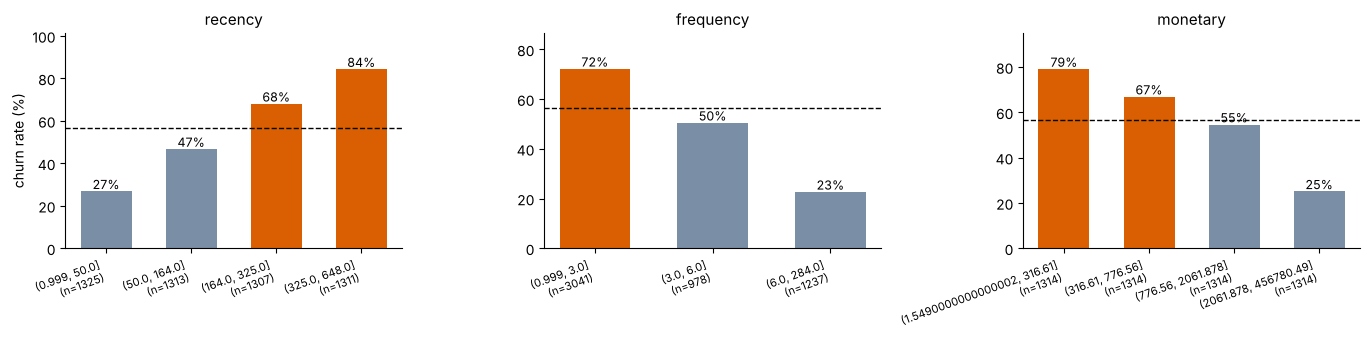

In [17]:
def churn_table(groups):
    # Churn rate (%) and number of customers for every group. `groups` = one group label per customer
    table = fe.loc[groups.index, "churn"].groupby(groups, observed=True).agg(customers="size", churn_rate="mean")
    table["churn_rate"] = (table["churn_rate"] * 100).round(1)
    return table


def quartiles(series):
    # 4 groups with (almost) the same number of customers; ties are merged
    return pd.qcut(series, 4, duplicates="drop")


def plot_churn(group_dict, ncols=3):
    # One small bar chart per entry: churn rate of each group vs the overall rate
    nrows = int(np.ceil(len(group_dict) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.6 * nrows), squeeze=False)
    for ax, (title, groups) in zip(axes.ravel(), group_dict.items()):
        table = churn_table(groups)
        labels = [f"{idx}\n(n={n})" for idx, n in zip(table.index, table["customers"])]
        colors = [COLOR_HIGH if r > overall_rate else COLOR_LOW for r in table["churn_rate"]]
        bars = ax.bar(labels, table["churn_rate"], color=colors, width=0.6)
        ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1)
        for bar, rate in zip(bars, table["churn_rate"]):
            ax.text(bar.get_x() + bar.get_width() / 2, rate + 1, f"{rate:.0f}%", ha="center", fontsize=9)
        ax.set_title(title, fontsize=11)
        ax.set_ylim(0, max(table["churn_rate"].max() * 1.2, overall_rate * 1.3))
        ax.tick_params(axis="x", labelsize=8)
        if max(len(str(i)) for i in table.index) > 9:
            plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    for ax in axes.ravel()[len(group_dict):]:
        ax.axis("off")
    axes[0][0].set_ylabel("churn rate (%)")
    plt.tight_layout()
    plt.show()


print(f"overall churn rate: {overall_rate:.1f}%")
plot_churn({"recency": quartiles(fe["recency"]),
            "frequency": quartiles(fe["frequency"]),
            "monetary": quartiles(fe["monetary"])})

**Gözlem:** Üç klasik sütun tam beklediğimiz gibi çalışıyor. Her sütunu eşit büyüklükte gruplara böldüğümüzde:

- **`recency`:** en yakın çeyrekte (son ~50 gün) churn **%27**, en uzak çeyrekte (325 günden eski) **%84**.
- **`frequency`:** 1-3 sipariş verenlerde **%72**, 7 ve üzeri sipariş verenlerde **%23**.
- **`monetary`:** en az harcayan çeyrekte **%79**, en çok harcayan çeyrekte **%25**.

Bu üç sütun bizim **baz modelimiz**: yeni özelliklerin işe yarayıp yaramadığını bunlara göre ölçeceğiz.

### 3.A Tazelik: müşteri en son ne zaman geldi?

| Özellik | Nasıl hesaplanır? | Neden Churn'ü etkileyebilir? | Beklentimiz |
|---|---|---|---|
| `recency_group` | `recency`'yi 0-30, 31-90, 91-180, 181-365, 366+ gün gruplarına böl (`pd.cut`) | Birkaç gündür gelmeyen ile bir yıldır gelmeyen çok farklı: kopuş aşamalı olur | Grup büyüdükçe churn **artar** |

**Python notu:** `pd.cut(sütun, sınırlar, labels=...)` değerleri **senin belirlediğin sınırlarla** gruplar. `pd.qcut` ise gruplara **eşit sayıda müşteri** koyar; `cut`'ta sınırı sen seçersin, `qcut`'ta veri seçer.

,customers,churn_rate
recency_group,,
0-30,935,24.8
31-90,968,36.9
91-180,880,53.8
181-365,1523,69.5
366+,950,89.2


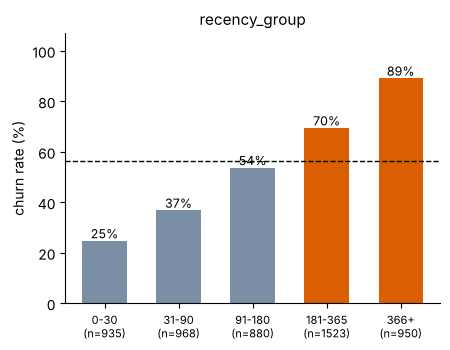

In [18]:
fe["recency_group"] = pd.cut(
    fe["recency"],
    bins=[-1, 30, 90, 180, 365, 10000],
    labels=["0-30", "31-90", "91-180", "181-365", "366+"],
)
new_features += ["recency_group"]

display(churn_table(fe["recency_group"]))
plot_churn({"recency_group": fe["recency_group"]}, ncols=1)

**Gözlem:** Tablo tam beklediğimiz gibi: son 30 günde alışveriş yapanlarda churn **%25**, bir yıldan uzun süredir gelmeyenlerde **%89**. Her basamakta artıyor (%25, %37, %54, %70, %89). Bu, `recency`'nin kendisinden daha **okunaklı** bir hali: "180 günden uzun süredir gelmeyen her 10 müşteriden 7-9'u bir daha gelmiyor".

### 3.B Sıklık ve ritim: kendi alışkanlığına göre geç mi kaldı?

Bir müşterinin **kendi ritmi** var: ayda bir sipariş veren bir müşteri için 45 gün sessizlik alarmdır; yılda iki sipariş veren için normaldir. Bu yüzden `recency` tek başına yetmez; **kendi ritmine göre** düşünmek gerekir.

| Özellik | Nasıl hesaplanır? | Neden Churn'ü etkileyebilir? | Beklentimiz |
|---|---|---|---|
| `is_single_order` | `frequency == 1` ise 1 | Tek sipariş veren, "deneyip bırakan" olabilir; bağlılığı henüz yok | 1 olanlarda churn **yüksek** |
| `avg_days_between_orders` | ilk ve son sipariş arası gün / (sipariş sayısı - 1) | Ritmi anlatır: kısa = sık alışveriş yapan | Uzadıkça churn **artar** |
| `overdue_ratio` | `recency / avg_days_between_orders` | "Normalde X günde bir gelir, şu an 3X gündür gelmedi": **kendi ritmine göre gecikme** | 1'i aştıkça churn **artar** |
| `orders_last_30d`, `orders_last_90d` | son 30 / 90 gündeki fatura sayısı | Yakın zamandaki aktivite, tüm geçmişten daha güncel bilgi | Aktif müşteri kalır |
| `orders_prev_90d`, `order_trend` | önceki 90 gün (180-90 gün önce) ve `orders_last_90d - orders_prev_90d` | Müşteri **yavaşlıyor mu**? | Yavaşlayanda churn **yüksek** (?) |

**Python notları:**

- `.where(koşul, değer)`: koşul **yanlışsa** satırı `değer` ile değiştirir. Tek siparişli müşteri için "ortalama bekleme" hesaplanamaz (aralık yok), onu **0** yapıyoruz. Bu "0 = hiç veri yok" demek, "çok sık geliyor" demek değil; bu yüzden `is_single_order` bayrağı da var.
- Zaman penceresindeki sipariş sayısını bulmak için ayrı bir fonksiyon yazıyoruz (`orders_between`); birkaç özellikte kullanacağız.

In [19]:
fe["is_single_order"] = (fe["frequency"] == 1).astype(int)

# Average gap between orders = days between first and last order / number of gaps (orders - 1)
span_days = (fe["last_purchase"] - fe["first_purchase"]).dt.days
fe["avg_days_between_orders"] = (span_days / (fe["frequency"] - 1)).where(fe["frequency"] > 1, 0)

# How late is the customer compared with HIS OWN rhythm? (single-order customers: 0 = no data)
safe_gap = fe["avg_days_between_orders"].replace(0, np.nan)
fe["overdue_ratio"] = (fe["recency"] / safe_gap).fillna(0)


def orders_between(start, end):
    # Number of distinct invoices of every customer inside [start, end); customers with none get 0
    window = hist[(hist["InvoiceDate"] >= start) & (hist["InvoiceDate"] < end)]
    return window.groupby("Customer ID")["Invoice"].nunique().reindex(fe.index).fillna(0)


day = pd.Timedelta(days=1)
fe["orders_last_30d"] = orders_between(cutoff - 30 * day, cutoff)
fe["orders_last_90d"] = orders_between(cutoff - 90 * day, cutoff)
fe["orders_prev_90d"] = orders_between(cutoff - 180 * day, cutoff - 90 * day)

# Trend: positive = more orders in the last 90 days than in the 90 days before (speeding up)
fe["order_trend"] = fe["orders_last_90d"] - fe["orders_prev_90d"]

new_features += ["is_single_order", "avg_days_between_orders", "overdue_ratio",
                 "orders_last_30d", "orders_last_90d", "orders_prev_90d", "order_trend"]

fe[["frequency", "recency", "is_single_order", "avg_days_between_orders", "overdue_ratio",
    "orders_last_30d", "orders_last_90d", "orders_prev_90d", "order_trend"]].round(1).head()

,frequency,recency,is_single_order,avg_days_between_orders,overdue_ratio,orders_last_30d,orders_last_90d,orders_prev_90d,order_trend
Customer ID,,,,,,,,,
12346,3,235,0,160.5,1.5,0.0,0.0,0.0,0.0
12347,6,39,0,54.8,0.7,0.0,1.0,2.0,-1.0
12348,4,158,0,63.0,2.5,0.0,0.0,1.0,-1.0
12349,2,317,0,181.0,1.8,0.0,0.0,0.0,0.0
12350,1,220,1,0.0,0.0,0.0,0.0,0.0,0.0


--- is_single_order


,customers,churn_rate
is_single_order,,
0,3681,46.6
1,1575,79.4


--- avg_days_between_orders (2+ orders)


,customers,churn_rate
avg_days_between_orders,,
"(-0.001, 38.25]",922,37.0
"(38.25, 67.429]",919,38.5
"(67.429, 116.5]",920,47.9
"(116.5, 632.0]",920,63.0


--- overdue_ratio (2+ orders)


,customers,churn_rate
overdue_ratio,,
<0.5,1022,38.2
0.5-1,623,35.0
1-2,723,40.5
2-4,587,52.1
4+,726,70.1


... (2 outputs left out)

--- orders_last_90d


,customers,churn_rate
orders_last_90d,,
0,3364,70.8
1,1073,41.3
2,428,25.7
3+,391,8.4


--- order_trend


,customers,churn_rate
order_trend,,
slowing,1223,43.2
same,2946,68.8
speeding up,1087,37.8


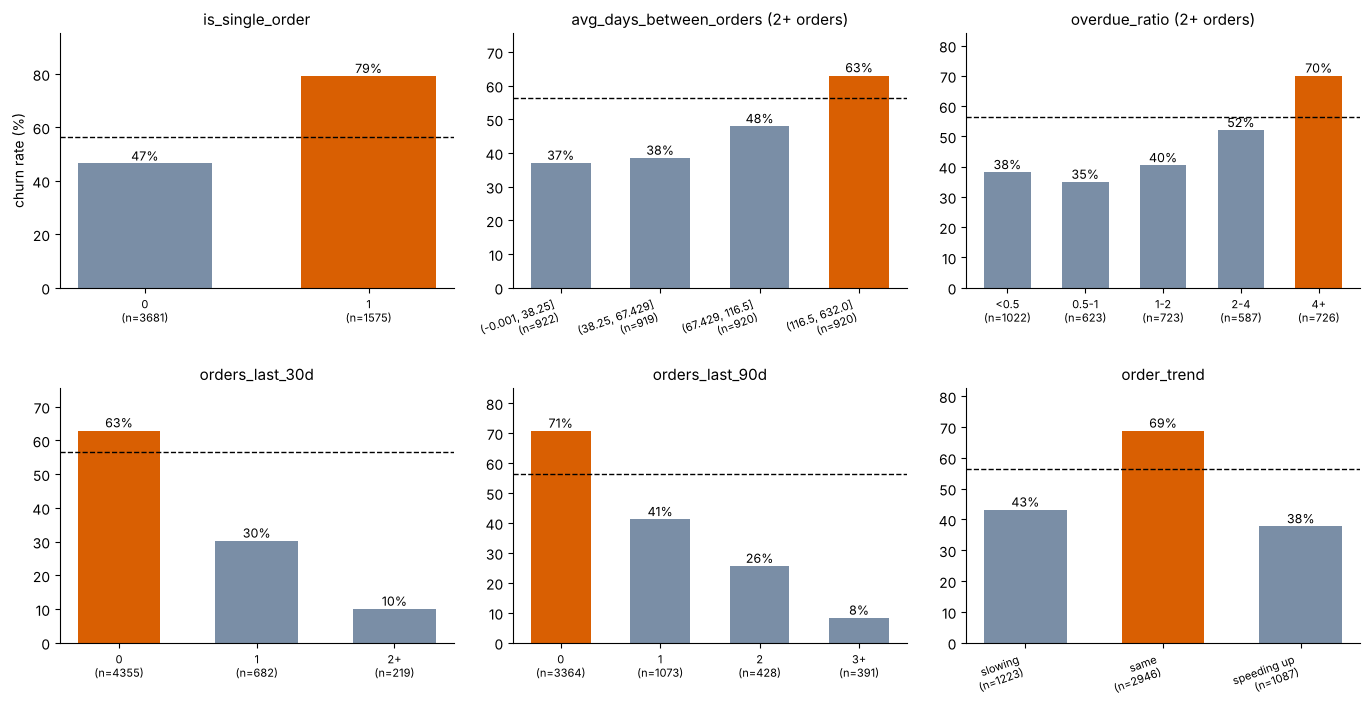

In [20]:
# Test. Features that need "at least 2 orders" are tested only on customers with 2+ orders
multi = fe[fe["frequency"] > 1]

groups = {
    "is_single_order": fe["is_single_order"],
    "avg_days_between_orders (2+ orders)": quartiles(multi["avg_days_between_orders"]),
    "overdue_ratio (2+ orders)": pd.cut(multi["overdue_ratio"], [-0.01, 0.5, 1, 2, 4, 10000],
                                        labels=["<0.5", "0.5-1", "1-2", "2-4", "4+"]),
    "orders_last_30d": pd.cut(fe["orders_last_30d"], [-1, 0, 1, 10000], labels=["0", "1", "2+"]),
    "orders_last_90d": pd.cut(fe["orders_last_90d"], [-1, 0, 1, 2, 10000], labels=["0", "1", "2", "3+"]),
    "order_trend": pd.cut(fe["order_trend"], [-10000, -1, 0, 10000], labels=["slowing", "same", "speeding up"]),
}
for title, g in groups.items():
    print("---", title)
    display(churn_table(g))
plot_churn(groups)

**Gözlem:** - `is_single_order`: tek sipariş verenlerde churn **%79**, 2 ve üzeri sipariş verenlerde **%47**. "Deneyip bırakan" müşteri gerçek.
- `avg_days_between_orders` (2+ siparişli müşteriler): %37, %39, %48, %63. Ritmi yavaş olan müşteri daha çok kaybediliyor.
- **`overdue_ratio`: kendi ritmine göre gecikme net bir sinyal.** Normal ritminin yarısı ile bir katı arasında bekleyenlerde churn %35, 2-4 katını aşanlarda %52, **4 katından fazla** bekleyenlerde **%70**. Aynı 100 gün sessizlik, ayda bir gelen için alarm, yılda iki kez gelen için normal. `recency` bunu söyleyemez.
- `orders_last_30d` ve `orders_last_90d`: son 90 günde hiç siparişi olmayanlarda **%71**, 3 ve üzeri siparişi olanlarda **%8**. Yakın zamandaki aktivite çok güçlü.
- **`order_trend` hipotezimizi bozdu.** Yavaşlayanlarda churn %43, hızlananlarda %38 ama "aynı" grupta **%69**. Neden? "Aynı" grubun (2.946 müşteri) **2.476'sı** son 90 günde de, önceki 90 günde de hiç sipariş vermemiş (0 - 0): yani zaten kopmuş, churn'leri %77. Aktif olup "aynı" kalanlar ise (470 müşteri) sadece %26. **"Fark = 0" iki farklı kitleyi karıştırıyor**: Telco'daki `n_addons` tuzağının aynısı.

### 3.C Harcama ve ürün çeşitliliği

| Özellik | Nasıl hesaplanır? | Neden Churn'ü etkileyebilir? | Beklentimiz |
|---|---|---|---|
| `avg_order_value` | `monetary / frequency` (sipariş başına ortalama harcama) | Büyük sipariş veren, işini bize dayandıran bir toptancı olabilir | Büyüdükçe churn **azalır** |
| `n_products` | kaç **farklı** `StockCode` aldı | Çok çeşit alan müşteri kataloğumuza bağlı; tek ürün alan kolay vazgeçer | Arttıkça churn **azalır** |
| `avg_items_per_order` | toplam adet / sipariş sayısı | Sipariş büyüklüğü: toptancı mı, deneme alışverişi mi? | Büyüdükçe churn **azalır** |

--- avg_order_value


,customers,churn_rate
avg_order_value,,
"(1.5490000000000002, 173.884]",1314,71.0
"(173.884, 275.149]",1314,55.6
"(275.149, 407.238]",1314,50.3
"(407.238, 25784.32]",1314,48.9


--- n_products


,customers,churn_rate
n_products,,
"(0.999, 18.0]",1363,76.9
"(18.0, 41.0]",1284,67.1
"(41.0, 92.0]",1304,53.9
"(92.0, 2178.0]",1305,27.1


--- avg_items_per_order


,customers,churn_rate
avg_items_per_order,,
"(0.999, 88.0]",1319,69.1
"(88.0, 149.0]",1313,58.1
"(149.0, 254.083]",1310,50.3
"(254.083, 87167.0]",1314,48.2


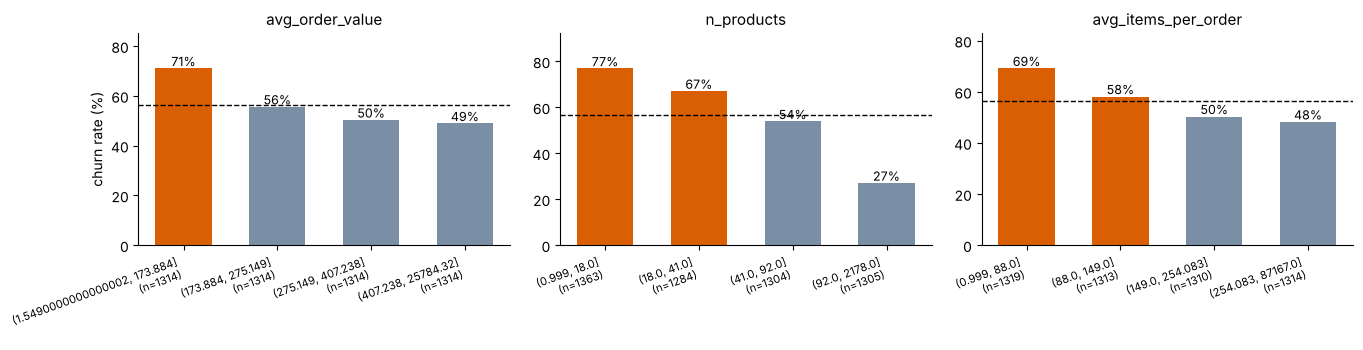

In [21]:
fe["avg_order_value"] = fe["monetary"] / fe["frequency"]
fe["n_products"] = hist.groupby("Customer ID")["StockCode"].nunique()
fe["avg_items_per_order"] = hist.groupby("Customer ID")["Quantity"].sum() / fe["frequency"]

new_features += ["avg_order_value", "n_products", "avg_items_per_order"]

groups = {col: quartiles(fe[col]) for col in ["avg_order_value", "n_products", "avg_items_per_order"]}
for title, g in groups.items():
    print("---", title)
    display(churn_table(g))
plot_churn(groups)

**Gözlem:** - `avg_order_value`: en küçük sipariş veren çeyrekte churn **%71**, en büyük sipariş veren çeyrekte **%49**. Yön doğru ama diğerlerine göre zayıf.
- **`n_products`: güçlü sinyal.** En çok 18 çeşit ürün almışlarda churn **%77**, 92'den fazla çeşit alanlarda **%27**. Kataloğumuzun geniş bir kısmını kullanan müşteri bize bağlı.
- `avg_items_per_order`: %69'dan %48'e düşüyor, `avg_order_value` gibi orta güçte.

### 3.D İade: ürünleri geri gönderiyor mu?

Burada dikkatli olmak gerekiyor: **çok alışveriş yapan müşteri doğal olarak daha çok iade de eder.** Yani "iade sayısı" aslında "çok alışveriş yapıyor" demek olabilir ve bu da churn'ü **azaltır**. O yüzden hem sayıya hem **orana** bakıyoruz.

| Özellik | Nasıl hesaplanır? | Neden Churn'ü etkileyebilir? | Beklentimiz |
|---|---|---|---|
| `n_returns` | iade faturası sayısı | İade eden müşteri bizimle **ilişki kuruyor** | Yön belirsiz, test edelim |
| `has_returned` | `n_returns > 0` ise 1 | Aynı bilgi, bayrak olarak | Yön belirsiz |
| `return_rate` | iade tutarı / harcama | Harcamasının büyük kısmını iade eden memnun değil | Yüksekse churn **artar** |
| `net_monetary` | `monetary - iade tutarı` | Gerçekte ödediği tutar | Düşükse churn **artar** |

--- has_returned


,customers,churn_rate
has_returned,,
0,3101,66.8
1,2155,41.5


--- return_rate


,customers,churn_rate
return_rate,,
0,3101,66.8
0-5%,1618,35.5
5-20%,421,56.3
20%+,116,71.6


--- net_monetary


,customers,churn_rate
net_monetary,,
"(-1663.061, 310.048]",1314,79.1
"(310.048, 758.345]",1314,67.4
"(758.345, 2002.195]",1314,54.2
"(2002.195, 454202.09]",1314,25.2


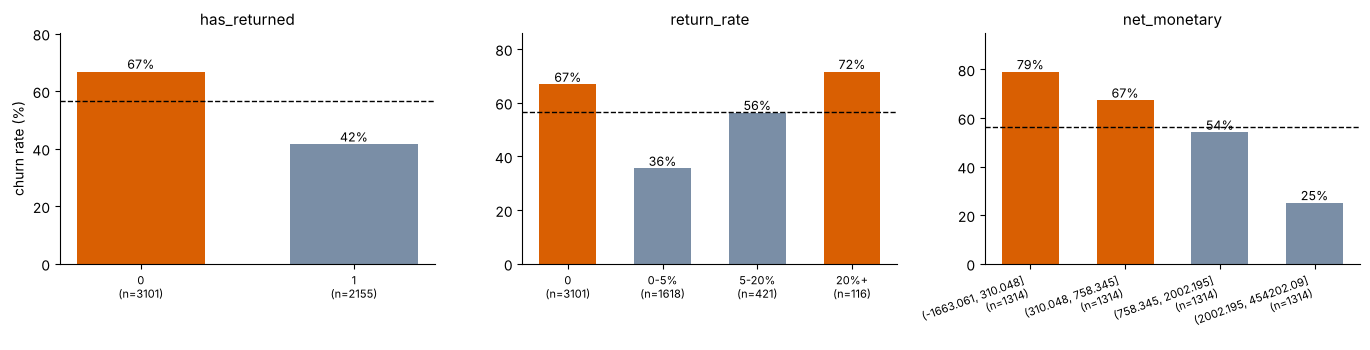

In [22]:
# Returns before the cutoff: number of return invoices and money returned (positive numbers)
ret = hist_returns.groupby("Customer ID").agg(n_returns=("Invoice", "nunique"), return_value=("return_value", "sum"))
ret = ret.reindex(fe.index).fillna(0)       # customers without returns -> 0

fe["n_returns"] = ret["n_returns"]
fe["has_returned"] = (fe["n_returns"] > 0).astype(int)
fe["return_rate"] = ret["return_value"] / fe["monetary"]     # 1.0 = returned everything
fe["net_monetary"] = fe["monetary"] - ret["return_value"]    # what the customer really paid

new_features += ["n_returns", "has_returned", "return_rate", "net_monetary"]

groups = {
    "has_returned": fe["has_returned"],
    "return_rate": pd.cut(fe["return_rate"], [-0.01, 0, 0.05, 0.2, 10000], labels=["0", "0-5%", "5-20%", "20%+"]),
    "net_monetary": quartiles(fe["net_monetary"]),
}
for title, g in groups.items():
    print("---", title)
    display(churn_table(g))
plot_churn(groups)

**Gözlem:** İade tarafında **yön belirsiz** demiştik; tablolar nedenini gösteriyor:

- `has_returned`: iade edenlerde churn **%42**, etmeyenlerde **%67**. İade eden müşteri **daha az** kopuyor! Çünkü çok alışveriş yapan müşteri doğal olarak iade de eder: bu özellik aslında "etkin müşteri" demek.
- `return_rate`: iade **oranına** bakınca hikâye değişiyor. Hiç iade etmeyenler %67; ama iade edenlerin içinde oran büyüdükçe churn artıyor: %36 (0-5%), %56 (5-20%), **%72** (%20 üzeri). Harcamasının büyük kısmını iade eden müşteri memnun değil.
- `net_monetary`: iadeler düşülmüş gerçek harcama çok güçlü: en düşük çeyrekte **%79**, en yüksek çeyrekte **%25**.

**Ders:** Aynı olay (iade) iki farklı özellikte **zıt** sinyal veriyor. Sayıya (kaç kez) ve orana (ne kadarını) ayrı ayrı bakmak gerekir.

### 3.E Zaman ve mevsim: ne zamandır müşteri, geçen yıl bu dönemde ne yaptı?

Bu veride bir **mevsim** etkisi bekliyoruz: ürünlerin çoğu hediyelik ve ev eşyası, yani sonbahar-kış (Noel) dönemi önemli. Tahmin penceremiz (11 Eylül - 10 Aralık) tam bu sezonu kapsıyor. Bir müşteri **geçen yıl aynı dönemde** alışveriş yaptıysa, bu yıl da yapması beklenir. Bu bilgi **RFM'de yok**: `recency` sadece son alışverişe bakar, bir yıl önceki alışkanlığa değil.

| Özellik | Nasıl hesaplanır? | Neden Churn'ü etkileyebilir? | Beklentimiz |
|---|---|---|---|
| `tenure` | `cutoff` - ilk alışveriş (gün) | Eski müşteri bağlıdır | Büyüdükçe churn **azalır** |
| `n_active_months` | kaç **farklı ayda** alışveriş yaptı | Düzenli müşteri çok ayda görünür | Arttıkça churn **azalır** |
| `same_window_flag` | geçen yıl aynı 90 günlük pencerede (cutoff - 365 ile cutoff - 275 gün arası) sipariş verdiyse 1 | **Mevsimsel alışkanlık**: geçen Noel'de aldı, bu Noel'de de alır | 1 olanlarda churn **düşük** |
| `q4_share` | siparişlerinin kaçı Ekim-Aralık'ta | Sadece Noel'de alışveriş yapan "sezonluk" müşteri | Yüksekse churn **düşük** (?) |

--- tenure


,customers,churn_rate
tenure,,
"(0.999, 311.0]",1317,57.3
"(311.0, 474.0]",1321,62.8
"(474.0, 587.0]",1325,60.5
"(587.0, 648.0]",1293,45.0


--- n_active_months


,customers,churn_rate
n_active_months,,
1,1718,78.3
2,962,68.2
3-4,1055,53.2
5+,1521,26.6


--- same_window_flag


,customers,churn_rate
same_window_flag,,
0,2389,70.5
1,2867,44.7


--- q4_share


,customers,churn_rate
q4_share,,
0%,2302,68.2
up to 50%,2076,38.6
over 50%,878,68.0


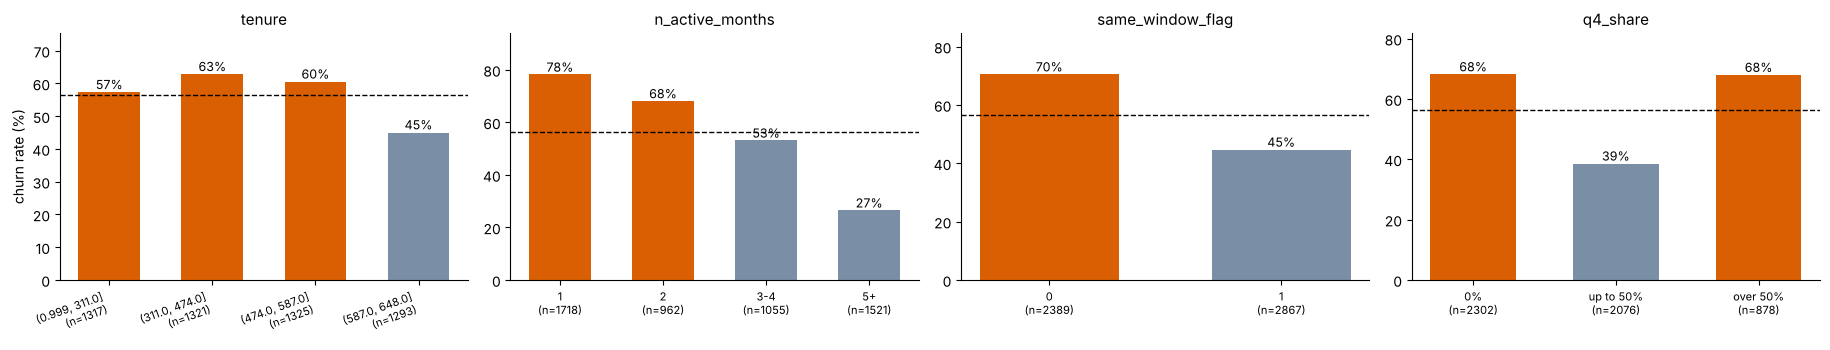

In [23]:
fe["tenure"] = (cutoff - fe["first_purchase"]).dt.days

# Number of different calendar months with at least one purchase
month = hist["InvoiceDate"].dt.to_period("M")
fe["n_active_months"] = hist.groupby([hist["Customer ID"], month]).size().groupby("Customer ID").size()

# Seasonal habit: did the customer buy in the SAME 90-day window one year earlier?
# (Sep 11 - Dec 9 of the year before the cutoff)
same_window_orders = orders_between(cutoff - 365 * day, cutoff - 275 * day)
fe["same_window_flag"] = (same_window_orders > 0).astype(int)

# Share of the customer's orders placed in October-December
invoices = hist.groupby(["Customer ID", "Invoice"])["InvoiceDate"].min().reset_index()
invoices["is_q4"] = invoices["InvoiceDate"].dt.month.isin([10, 11, 12])
fe["q4_share"] = invoices.groupby("Customer ID")["is_q4"].mean()

new_features += ["tenure", "n_active_months", "same_window_flag", "q4_share"]

groups = {
    "tenure": quartiles(fe["tenure"]),
    "n_active_months": pd.cut(fe["n_active_months"], [0, 1, 2, 4, 100], labels=["1", "2", "3-4", "5+"]),
    "same_window_flag": fe["same_window_flag"],
    "q4_share": pd.cut(fe["q4_share"], [-0.01, 0, 0.5, 1], labels=["0%", "up to 50%", "over 50%"]),
}
for title, g in groups.items():
    print("---", title)
    display(churn_table(g))
plot_churn(groups, ncols=4)

**Gözlem:** - `tenure`: beklediğimiz gibi düz bir merdiven **değil**: 311-587 gündür müşteri olanlar en çok kopuyor (%60-63), en eski çeyrek %45. Veri sadece 2 yıllık olduğu için "eski müşteri" sınırlı bir kavram.
- `n_active_months`: net ve güçlü: tek ayda alışveriş yapmış müşteride **%78**, 5 ve üzeri farklı ayda alışveriş yapmışlarda **%27**.
- **`same_window_flag`: mevsimsel hipotez tuttu.** Geçen yıl aynı dönemde (11 Eylül - 9 Aralık 2010) alışveriş yapmış müşterilerin churn'ü **%45**, yapmamışlarda **%70,5**. Bu, RFM'in göremediği bir bilgi: `recency` sadece son alışverişe bakar, bir yıl önceki alışkanlığa değil.
- **`q4_share` hipotezimizi bozdu.** "Sezonluk müşteri geri gelir" demiştik; sonuç **U şeklinde**: hiç Ekim-Aralık alışverişi olmayan %68, yarısından fazlası Ekim-Aralık olan %68, ortadakiler %39. Yani yıl boyunca dağılmış alışveriş yapan müşteri en bağlı olanı. (Telco'da `n_services` de böyle çıkıntılı çıkmıştı.)

### 3.F Müşteri profili: hangi ülkeden?

Müşteriler 40'tan fazla ülkeden. Çoğu İngiltere'de. Çok sayıda **küçük ülke** var (bazılarında çok az müşteri). Her ülkeye ayrı bir sütun açmak (bölüm 4'te göreceğiz: one-hot) hem çok sütun üretir hem de küçük ülkelerin oranı **güvenilmez** olur (2 müşterinin churn oranı %50 ya da %100 çıkabilir, tesadüf).

| Özellik | Nasıl hesaplanır? | Neden Churn'ü etkileyebilir? | Beklentimiz |
|---|---|---|---|
| `country_group` | en kalabalık 4 ülke kendi adıyla, **geri kalan hepsi "Other"** | Ülke farkı (kargo süresi, rakipler, para birimi) bağlılığı etkileyebilir | Belirsiz, test edelim |

Bu bir **nadir kategorileri birleştirme** tekniği: az örneği olan değerleri tek çatı altında toplarız.

,customers,churn_rate
country_group,,
France,76,42.1
Germany,92,40.2
Other,258,61.6
Spain,31,48.4
United Kingdom,4799,56.8


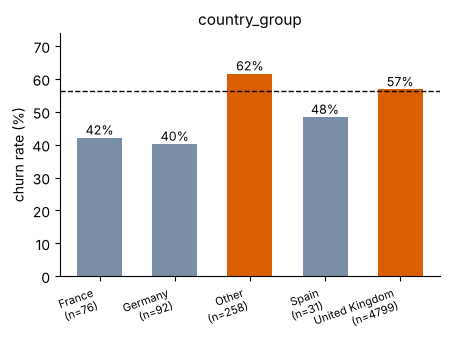

In [24]:
fe["country"] = hist.groupby("Customer ID")["Country"].last()     # country of the most recent order

top_countries = fe["country"].value_counts().head(4).index
fe["country_group"] = fe["country"].where(fe["country"].isin(top_countries), "Other")
new_features += ["country_group"]

display(churn_table(fe["country_group"]))
plot_churn({"country_group": fe["country_group"]}, ncols=1)

**Gözlem:** Fark küçük ve **güvenilmez**: İngiltere %57, Almanya %40, Fransa %42, İspanya %48, diğerleri %62. Almanya, Fransa ve İspanya'da müşteri sayısı 31-92 gibi çok az, bu yüzden oranlar tesadüfen oynayabilir. Ülke bu veride güçlü bir özellik **değil**; hipotezi test ettik, iddialı olmadan bırakıyoruz.

### 3.G Üretilen özelliklerin özeti ve kullandığımız teknikler

| Özellik | Teknik |
|---|---|
| `recency_group` | **Gruplama:** sayıyı kendi seçtiğimiz sınırlarla böl (`pd.cut`) |
| `is_single_order` | **Bayrak:** koşul doğruysa 1 |
| `avg_days_between_orders` | **Oran:** süre / aralık sayısı |
| `overdue_ratio` | **Oran:** iki özelliği birbirine böl (kendi ritmine göre gecikme) |
| `orders_last_30d`, `orders_last_90d`, `orders_prev_90d` | **Zaman penceresi:** belirli bir tarih aralığındaki olayları say |
| `order_trend` | **Fark:** yakın dönem - önceki dönem (eğilim) |
| `avg_order_value`, `avg_items_per_order` | **Oran:** toplam / sipariş sayısı |
| `n_products` | **Benzersiz sayma:** `nunique` |
| `n_returns`, `has_returned`, `return_rate`, `net_monetary` | **İkinci tablodan özet** (iadeler) ve oran / fark |
| `tenure` | **Tarih farkı:** referans tarih - ilk alışveriş |
| `n_active_months` | **Benzersiz sayma:** kaç farklı ay |
| `same_window_flag` | **Geçmiş dönem karşılaştırması:** geçen yılın aynı penceresi |
| `q4_share` | **Oran:** belirli bir mevsimdeki payı |
| `country_group` | **Nadir kategorileri birleştirme** |

**Üretmediklerimiz:** `Customer ID` (kimlik, özellik değil), `Description` (ürün adı: yazıdan özellik çıkarmak ayrı bir konu), ürün kategorileri (veride yok).

**Veride olsaydı üretebileceğimiz özellikler:**

| Veri | Üretilecek özellik |
|---|---|
| Müşteri şikayet / destek kayıtları | Çözülmemiş şikayet sayısı |
| Kampanya / e-posta geçmişi | Son kampanyaya yanıt verdi mi? |
| Ürün kategorisi | En çok aldığı kategori, kategoriye bağlılık |
| Teslimat bilgisi | Geciken siparişlerin oranı |
| Rakip fiyatları | Fiyat farkı |

**Soru (sınıfa):** Hangi özellik sizce **sızıntı riski** taşır? (İpucu: bir özelliğin hesabında `hist` yerine `sales` yazsaydık ne olurdu?)

## Adım 4. Encoding (sayıya çevirme) ve scaling (ölçekleme)

Makine öğrenmesi modelleri **sayılarla** çalışır. Yazı (kategori) sütunlarını sayıya çevirmeye **encoding** deniyor. Yöntem sütunun türüne bağlı:

| Sütun türü | Bu notebook'ta | Yöntem |
|---|---|---|
| **İkili** (0/1) | `is_single_order`, `has_returned`, `same_window_flag` | Zaten 0/1 |
| **Sıralı** (doğal sırası var) | `recency_group` (0-30 < 31-90 < ...) | **Sıra numarası:** ordinal encoding |
| **Sırasız** (3+ değer, sıra yok) | `country_group` (UK, Germany, ...) | **One-hot:** her değere ayrı 0/1 sütunu |
| **Kimlik / tarih** | `Customer ID`, `first_purchase`, `last_purchase` | **Atılır:** modelde işe yaramaz (tarihlerden zaten `recency` ve `tenure` türettik) |

**Neden sırasız kategorilere 0, 1, 2 vermiyoruz?** `UK = 0`, `Germany = 1`, `France = 2` desek model "France, UK'nin iki katı" gibi **sahte bir sıra** öğrenir. One-hot bu sorunu çözer. `drop_first=True` ile bir sütunu atıyoruz: hepsi 0 ise o atılan değerdir (fazladan sütun gereksiz tekrar olur).

In [25]:
data = fe.copy()

# Ordinal encoding: the groups have a natural order, so their order number is meaningful (0 = most recent)
data["recency_group"] = data["recency_group"].cat.codes

# One-hot encoding: one 0/1 column per country group; the first (alphabetical) one is dropped
data = pd.get_dummies(data, columns=["country_group"], drop_first=True, dtype=int)

# Drop what the model cannot or should not use: dates, the raw country text
data = data.drop(columns=["first_purchase", "last_purchase", "country"])

y = data["churn"]
X = data.drop(columns=["churn"])

# Final checks: everything must be numeric and nothing may be missing
print("shape of X:", X.shape)
print("non-numeric columns:", [c for c in X.columns if X[c].dtype.kind not in "iuf"])
print("missing values:", int(X.isna().sum().sum()))
print("country columns:", [c for c in X.columns if c.startswith("country_group_")])

shape of X: (5256, 26)
non-numeric columns: []
missing values: 0
country columns: ['country_group_Germany', 'country_group_Other', 'country_group_Spain', 'country_group_United Kingdom']


Tablomuz hazır: **sadece sayı, eksik yok.**

### Scaling (ölçekleme)

Sayısal sütunların **ölçekleri çok farklı**: `recency` 0-700 gün, `monetary` binlerce, `frequency` 1-200. Logistic Regression, KNN, SVM gibi modeller sütunları büyüklüğüne göre tartar; büyük ölçekli sütun, önemsiz olsa bile diğerlerini ezer. Çözüm: sütunları **aynı ölçeğe** getirmek (`StandardScaler`: ortalama 0, standart sapma 1).

Bu veride bir sorun daha var: **çarpıklık.** Çoğu müşteri az harcıyor, birkaçı çok büyük harcıyor (toptancılar). Dağılım sağa doğru uzun bir kuyruk bırakıyor. Bu kuyruk, ölçeklemeden sonra bile modelleri bozar. Çözüm: **log dönüşümü** (`np.log1p`): büyük sayıları sıkıştırır, küçükleri neredeyse olduğu gibi bırakır. **Sıralamayı bozmaz.** Bakalım ne kadar çarpık:

In [26]:
# Skewness: 0 = symmetric; large positive = a long tail to the right (a few very big values)
numeric_cols = ["recency", "tenure", "frequency", "monetary", "avg_days_between_orders", "orders_last_30d",
                "orders_last_90d", "orders_prev_90d", "avg_order_value", "n_products", "avg_items_per_order",
                "n_returns", "return_rate", "net_monetary", "n_active_months", "overdue_ratio"]

skew_table = pd.DataFrame({
    "skew_before": X[numeric_cols].skew(),
    "skew_after_log1p": np.log1p(X[numeric_cols].clip(lower=0)).skew(),   # clip: net_monetary can be negative
}).round(2)

# Reading the table: most columns get much closer to 0 after log1p
skew_table

,skew_before,skew_after_log1p
recency,0.67,-0.96
tenure,-0.63,-2.57
frequency,10.49,1.06
monetary,23.99,0.28
avg_days_between_orders,2.20,-0.46
orders_last_30d,6.19,2.45
orders_last_90d,9.14,1.54
orders_prev_90d,8.14,1.48
avg_order_value,20.38,-0.04
n_products,6.12,-0.25


**Gözlem:** Çarpıklık (skew) 0'a ne kadar yakınsa dağılım o kadar simetrik. `frequency` (10,5), `monetary` (24,0), `avg_items_per_order` (48,0) çok uzun bir sağ kuyruğa sahip: birkaç dev müşteri ortalamayı çekiyor. `log1p`'ten sonra bunlar 0'a yaklaşıyor. Ama her sütunda işe yaramıyor: `recency` ve `tenure` zaten çarpık değil ve log onları **ters yönde** çarpıklaştırıyor (`tenure`: -0,63 → -2,57).

**Karar:** `log1p`'i sadece çarpıklığı belirgin azalan sütunlara uyguluyoruz: `frequency`, `monetary`, `avg_order_value`, `n_products`, `avg_items_per_order`, `net_monetary` gibi. **`recency` ve `tenure`'a uygulamıyoruz.** Yani "her sütuna log at" diye bir kural yok: önce çarpıklığa bakıyoruz. `return_rate` (14,5 → 8,2) log'dan sonra da hâlâ çarpık; bu kadarıyla devam ediyoruz.

Ağaç modelleri (Random Forest gibi) dönüşümlerden **etkilenmez**; bu yüzden log + scaling'i yalnızca Logistic Regression'a uygulayacağız.

> **En önemli kural (sızıntı, yine):** Scaler'ı **önce train (eğitim) verisine** göre öğreniyoruz (`fit`), sonra hem train'e hem test'e uyguluyoruz (`transform`). Önce bütün veriyi ölçeklersek test verisinin ortalaması train'e sızar. Bu yüzden **önce bölüyoruz, sonra ölçekliyoruz.**

In [27]:
# 80% train / 20% test. stratify=y keeps the same churn rate in both parts.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)
print("churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

# Columns that get log1p: the skewed ones. recency and tenure are NOT in the list (log would make them worse)
log_cols = ["frequency", "monetary", "avg_days_between_orders", "orders_last_30d", "orders_last_90d",
            "orders_prev_90d", "avg_order_value", "n_products", "avg_items_per_order", "n_returns",
            "return_rate", "net_monetary", "n_active_months", "overdue_ratio"]

# Columns that get scaled: the log columns plus recency, tenure and the ordinal group
scale_cols = log_cols + ["recency", "tenure", "recency_group"]

def log_transform(table):
    out = table.copy()
    out[log_cols] = np.log1p(out[log_cols].clip(lower=0))
    return out

X_train_log = log_transform(X_train)
X_test_log = log_transform(X_test)

scaler = StandardScaler()
scaler.fit(X_train_log[scale_cols])            # learn mean and std from TRAIN only

X_train_scaled = X_train_log.copy()
X_test_scaled = X_test_log.copy()
X_train_scaled[scale_cols] = scaler.transform(X_train_log[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test_log[scale_cols])   # same mean/std, learned from train

show = ["recency", "frequency", "monetary"]
print("before (train):")
display(X_train[show].describe().loc[["mean", "std", "min", "max"]].round(1))
print("after log1p + scaling (train): mean 0 and std 1 for every scaled column")
display(X_train_scaled[show].describe().loc[["mean", "std", "min", "max"]].round(2))

train: (4204, 26) | test: (1052, 26)
churn rate train: 0.564 | test: 0.565
before (train):


,recency,frequency,monetary
mean,208.9,5.7,2587.8
std,175.0,11.1,11386.5
min,1.0,1.0,1.6
max,648.0,284.0,456780.5


after log1p + scaling (train): mean 0 and std 1 for every scaled column


,recency,frequency,monetary
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.19,-1.01,-4.21
max,2.51,5.29,4.60


**Gözlem:** Ölçeklemeden önce `monetary` ortalama 2.588 (en büyüğü 456.780), `recency` ortalama 209, `frequency` ortalama 5,7: ölçekler binlerce kat farklı. Sonra üçünün de ortalaması 0, standart sapması 1. `frequency`'nin en büyük değeri hâlâ 5,3 standart sapma yukarıda: log sağ kuyruğu sıkıştırdı ama tamamen yok etmedi. Sıralama bozulmadı, sadece birim değişti.

## Adım 5. Hangi özellik işe yaradı?

Üç farklı açıdan bakacağız:

1. **Her sütun tek başına Churn'ü ne kadar ayırıyor?** (tek sütunluk AUC)
2. **Model hangi sütunlara güveniyor?** (Random Forest özellik önemi)
3. **Yeni özellikler gerçekten modeli iyileştiriyor mu?** (RFM ile RFM + yeni özellikler, aynı modelle)

### 5.1 Tek başına güç: AUC

**AUC nedir?** Rastgele bir **churn eden** ve rastgele bir **kalan** müşteri seçelim. Sütun değeri, churn eden müşteriyi daha riskli gösteriyor mu? AUC bu olasılıktır:

- **0.5**: yazı-tura gibi, sütun hiçbir şey söylemiyor.
- **1.0**: mükemmel ayırıyor.
- Sütunun yönü fark etmez (artınca churn artması da, azalması da aynı derecede iyi). O yüzden `0.5`'ten ne kadar **uzakta** olduğuna bakıyoruz.

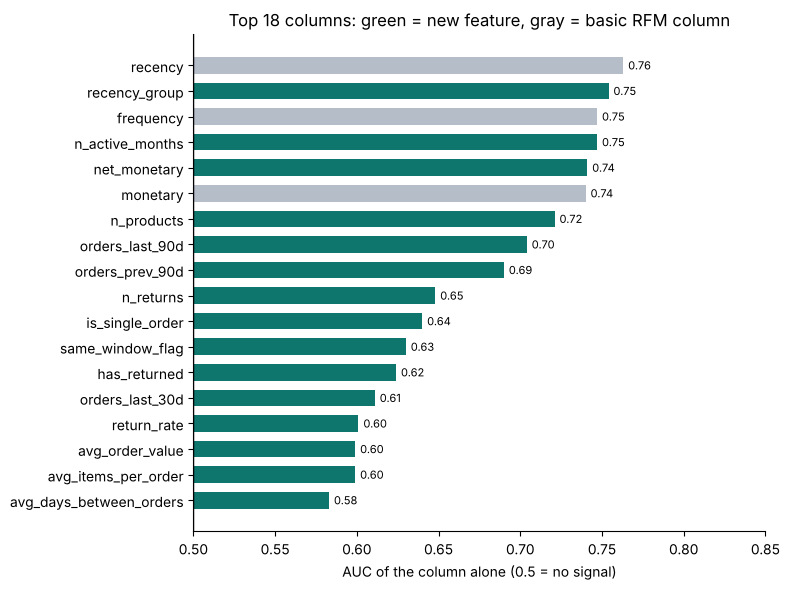

            column kind  auc_alone
0          recency  RFM      0.763
1    recency_group  new      0.754
2        frequency  RFM      0.747
3  n_active_months  new      0.747
4     net_monetary  new      0.741
5         monetary  RFM      0.740
6       n_products  new      0.721
7  orders_last_90d  new      0.704
8  orders_prev_90d  new      0.690
9        n_returns  new      0.648

                          column kind  auc_alone
18                 overdue_ratio  new      0.577
19                        tenure  new      0.547
20                      q4_share  new      0.544
21                   order_trend  new      0.510
22         country_group_Germany  new      0.506
23  country_group_United Kingdom  new      0.506
24           country_group_Other  new      0.505
25           country_group_Spain  new      0.501


In [28]:
base_cols = ["recency", "frequency", "monetary"]          # the classic RFM columns

rows = []
for col in X.columns:
    auc = roc_auc_score(y, X[col])
    rows.append((col, "RFM" if col in base_cols else "new", round(max(auc, 1 - auc), 3)))

power = pd.DataFrame(rows, columns=["column", "kind", "auc_alone"])
power = power.sort_values("auc_alone", ascending=False).reset_index(drop=True)

top = power.head(18).iloc[::-1]
colors = [COLOR_NEW if k == "new" else COLOR_RAW for k in top["kind"]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["column"], top["auc_alone"] - 0.5, left=0.5, color=colors, height=0.65)
for i, v in enumerate(top["auc_alone"]):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", fontsize=8)
ax.axvline(0.5, color="black", linewidth=1)
ax.set_xlim(0.5, 0.85)
ax.set_xlabel("AUC of the column alone (0.5 = no signal)")
ax.set_title("Top 18 columns: green = new feature, gray = basic RFM column")
plt.tight_layout()
plt.show()

# The strongest and the weakest columns
print(power.head(10).to_string())
print()
print(power.tail(8).to_string())

**Gözlem:** - **Zirvede baz RFM sütunları var:** `recency` (0,76), `frequency` (0,75), `monetary` (0,74). Yeni özelliklerden **bazıları aynı ligde**: `recency_group` (0,75, `recency`'nin gruplanmış hali, yeni bilgi değil), `n_active_months` (0,75), `net_monetary` (0,74), `n_products` (0,72), `orders_last_90d` (0,70). Ama bu tabloda **en iyi tek sütunu geçen yeni özellik yok**: en iyisi hâlâ `recency`.
- **Dipte:** `overdue_ratio` (0,58), `tenure` (0,55), `q4_share` (0,54), `order_trend` (0,51) ve ülke sütunları (yaklaşık 0,50). `order_trend` ve ülke Bölüm 3'te zaten zayıf çıkmıştı.
- **İki tuzak:**
  1. `overdue_ratio`'nun tablosunda net bir artış görmüştük (%35 → %70), ama tek başına AUC'si düşük çıktı. Sebep: tek siparişli müşterilere (yaklaşık %30'u) `0` koyduk ve bu sıfırlar sütunu karıştırıyor. Sadece 2+ siparişli müşterilerde bakınca AUC **0,64**'e çıkıyor. "0 = veri yok" doldurmasının bedeli bu.
  2. `q4_share` U şeklinde. AUC ve korelasyon gibi tek sayılık ölçüler "artınca artıyor ya da azalıyor" ilişkisini görür, U şeklini göremez.

### 5.2 Modele sorarak: Random Forest özellik önemi

Bir Random Forest'ı **bütün sütunlarla** eğitip hangi sütunlara en çok güvendiğine bakıyoruz.

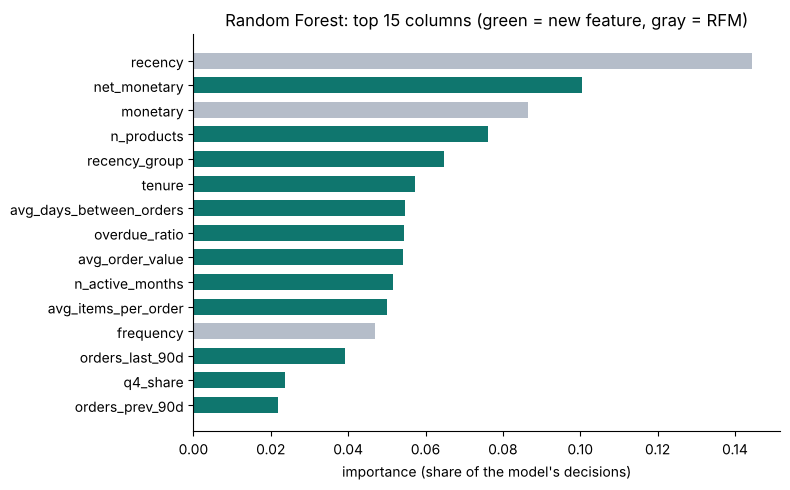

,importance
recency,0.144
net_monetary,0.100
monetary,0.086
n_products,0.076
recency_group,0.065
tenure,0.057
avg_days_between_orders,0.055
overdue_ratio,0.054
avg_order_value,0.054
n_active_months,0.052


In [29]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

top15 = importance.head(15).iloc[::-1]
colors = [COLOR_NEW if c not in base_cols else COLOR_RAW for c in top15.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top15.index, top15.values, color=colors, height=0.65)
ax.set_xlabel("importance (share of the model's decisions)")
ax.set_title("Random Forest: top 15 columns (green = new feature, gray = RFM)")
plt.tight_layout()
plt.show()

importance.head(15).round(3).to_frame("importance")

**Gözlem:** Random Forest en çok **`recency`**'ye güveniyor (%14). Ardından `net_monetary`, `monetary`, `n_products`, `recency_group`, `tenure`, `avg_days_between_orders`, `overdue_ratio`. Yeni özelliklerin birçoğu ilk 15'te.

**Dikkat (Telco'daki tuzak burada da var):**

1. **`tenure` 6. sırada** (0,057), ama tek başına AUC'si sadece 0,55 ve çeyrek tablosunda düz bir ilişki yoktu. Random Forest çok farklı değer alan sayısal sütunlarda çok sayıda bölme noktası deneyebildiği için bu tür sütunları **olduğundan önemli** gösterebilir. Öte yandan `same_window_flag` (0/1 bayrağı) ilk 15'te yok, oysa aşağıda göreceğimiz gibi Logistic Regression ve Gradient Boosting'e tutarlı katkı yaptı. Yani önem sıralaması **faydayı** değil, modelin sütunu ne kadar **kullandığını** gösterir.
2. Benzer sütunlar önemi bölüşür: `recency` ile `recency_group`, `monetary` ile `net_monetary` aynı bilgiyi taşıyor.

### 5.3 Yeni özellikler modeli gerçekten iyileştiriyor mu?

En önemli kıyas: aynı modelleri **farklı tablolarla** eğitiyoruz:

- **Sadece RFM:** `recency`, `frequency`, `monetary` (klasik baz model)
- **RFM + ritim, harcama, iade, profil:** zaman/mevsim özellikleri **hariç** bütün yeni özellikler
- **Hepsi:** zaman/mevsim özellikleri (`same_window_flag`, `n_active_months`, `q4_share`) dahil

Üç model deniyoruz: **Logistic Regression** (log + scaling ile), **Random Forest** ve **Gradient Boosting**. Test sonucu tek bir bölmeye çok bağlı olabilir; bu yüzden **5 farklı rastgele bölme** deneyip ortalamayı alıyoruz. Metrik **AUC** (0.5 = şans).

In [30]:
season_cols = ["same_window_flag", "n_active_months", "q4_share"]
column_sets = {
    "1) RFM only": base_cols,
    "2) RFM + rhythm, spend, returns, profile": [c for c in X.columns if c not in season_cols],
    "3) all (with time / season)": list(X.columns),
}


def evaluate(columns, seed):
    # Train three models on `columns`; return the test AUC of each
    X_tr, X_te, y_tr, y_te = train_test_split(X[columns], y, test_size=0.2, stratify=y, random_state=seed)

    # Logistic Regression needs log + scaling (fit on train only)
    log_here = [c for c in log_cols if c in columns]
    scale_here = [c for c in scale_cols if c in columns]
    X_tr_l, X_te_l = X_tr.copy(), X_te.copy()
    X_tr_l[log_here] = np.log1p(X_tr_l[log_here].clip(lower=0))
    X_te_l[log_here] = np.log1p(X_te_l[log_here].clip(lower=0))
    sc = StandardScaler().fit(X_tr_l[scale_here])
    X_tr_l[scale_here] = sc.transform(X_tr_l[scale_here])
    X_te_l[scale_here] = sc.transform(X_te_l[scale_here])

    lr = LogisticRegression(max_iter=3000).fit(X_tr_l, y_tr)
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    gb = HistGradientBoostingClassifier(random_state=42).fit(X_tr, y_tr)

    return {"Logistic Regression": roc_auc_score(y_te, lr.predict_proba(X_te_l)[:, 1]),
            "Random Forest": roc_auc_score(y_te, rf.predict_proba(X_te)[:, 1]),
            "Gradient Boosting": roc_auc_score(y_te, gb.predict_proba(X_te)[:, 1])}


results = []
for set_name, columns in column_sets.items():
    for seed in [42, 7, 21, 3, 99]:
        for model_name, auc in evaluate(columns, seed).items():
            results.append((set_name, model_name, seed, auc))

res = pd.DataFrame(results, columns=["columns", "model", "seed", "auc"])

# Mean AUC over the 5 splits: rows = model, columns = which table was used
mean_auc = res.groupby(["model", "columns"])["auc"].mean().unstack().round(4)
mean_auc

columns,1) RFM only,"2) RFM + rhythm, spend, returns, profile",3) all (with time / season)
model,,,
Gradient Boosting,0.7768,0.7839,0.7899
Logistic Regression,0.7904,0.7954,0.8015
Random Forest,0.7795,0.7957,0.7978


In [31]:
# Is the gain bigger than the random wobble between splits?
# For every split: AUC with all columns minus AUC with RFM only
pivot = res.pivot_table(index=["model", "seed"], columns="columns", values="auc")
pivot["gain_all_vs_rfm"] = pivot["3) all (with time / season)"] - pivot["1) RFM only"]
pivot["gain_season_only"] = pivot["3) all (with time / season)"] - pivot["2) RFM + rhythm, spend, returns, profile"]

# Reading the output: mean = average gain, std = how much it changes from split to split
pivot[["gain_all_vs_rfm", "gain_season_only"]].groupby("model").agg(["mean", "std", "min", "max"]).round(4)

columns             gain_all_vs_rfm                         gain_season_only                        
                               mean     std     min     max             mean     std     min     max
model                                                                                               
Gradient Boosting            0.0131  0.0090  0.0009  0.0244           0.0060  0.0035  0.0031  0.0121
Logistic Regression          0.0111  0.0049  0.0050  0.0168           0.0062  0.0042  0.0015  0.0108
Random Forest                0.0183  0.0091  0.0052  0.0285           0.0021  0.0034 -0.0037  0.0051

**Gözlem:** - **Sadece RFM'den tüm özelliklere** geçince AUC her üç modelde de artıyor: Logistic Regression 0,790 → 0,802, Random Forest 0,780 → 0,798, Gradient Boosting 0,777 → 0,790 (yani **+0,011 ile +0,018**). 5 bölmenin **hepsinde** artı: en küçük kazanç bile pozitif (0,001 ile 0,005 arası).
- **Mevsim/zaman özelliklerinin** (`same_window_flag`, `n_active_months`, `q4_share`) ek katkısı: Logistic Regression'da **+0,006** ve Gradient Boosting'de **+0,006**, ikisinde de 5 bölmenin hepsinde pozitif. Random Forest'ta sadece +0,002 ve bölmeden bölmeye eksi/artı değişiyor: gürültü seviyesinde.
- Kazanç **küçük ama tutarlı.** Telco'da gördüğümüzden (Logistic Regression'da +0,002, Random Forest'ta sıfır) büyük, ama "0,79'dan 0,90'a" gibi bir sıçrama değil.

**Neden büyük değil?** Baz tabloda (`recency`, `frequency`, `monetary`) en güçlü sinyaller zaten var; yeni özelliklerin çoğu onların farklı görünümleri. Üstelik churn'ü belirleyen şeylerin bir kısmı (müşterinin işi, fiyat, rakip kampanyası, şikayet) bu veride hiç yok. **Gerçek kazanç yeni bilgiden gelir**: `same_window_flag` (geçen yılın alışkanlığı) bu yüzden RFM'e gerçekten bir şey kattı.

### 5.4 Tuzak: "çok iyi" görünen özellik

Şimdi bilerek **yanlış** bir şey yapalım. `recency`'yi `cutoff`'a göre değil, **verideki son tarihe göre** hesaplayalım. Yani gelecekteki alışverişleri de dahil edelim. Bu, sızıntının en sinsi şekli: kodda tek kelime fark ediyor (`hist` yerine `sales`).

In [32]:
# WRONG on purpose: last purchase over ALL data, including the 90 days AFTER the cutoff (the future!)
last_any = sales.groupby("Customer ID")["InvoiceDate"].max().reindex(fe.index)
recency_leaky = (data_end - last_any).dt.days

auc_leaky = roc_auc_score(y, recency_leaky)
auc_right = roc_auc_score(y, X["recency"])
print(f"AUC of the correct recency (cutoff based) : {max(auc_right, 1 - auc_right):.3f}")
print(f"AUC of the leaky recency (uses the future): {max(auc_leaky, 1 - auc_leaky):.3f}")

# What would a model say? (same split as before)
leaky_X = X.assign(recency_leaky=recency_leaky)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(leaky_X, y, test_size=0.2, stratify=y, random_state=42)
model_leaky = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xl_tr, yl_tr)
print(f"Random Forest AUC with the leaky column added: {roc_auc_score(yl_te, model_leaky.predict_proba(Xl_te)[:, 1]):.3f}")

AUC of the correct recency (cutoff based) : 0.763
AUC of the leaky recency (uses the future): 1.000


Random Forest AUC with the leaky column added: 1.000


**Gözlem:** Yanlış hesaplanan `recency`'nin AUC'si **1.000**: **mükemmel.** Gerçek `recency` 0,76'ydı. Random Forest de bu sütun eklenince 1.000 veriyor. Sebep: gelecekteki alışverişi de içeriyor. Son 90 günde alışveriş yapan müşterinin yanlış `recency`'si en fazla 90, yapmayanlarınki 90'dan büyük; sütun cevabı doğrudan söylüyor.

**Bu, bir "başarı" değil, bir alarm.** Gerçek hayatta bu model yarın hiç çalışmaz, çünkü yarın "gelecek" henüz yok. Kural: **sonuç çok iyi görünüyorsa önce sızıntıyı ara.**

### 5.5 Bugün ne öğrendik?

| # | Çıkarım |
|---|---|
| 1 | Burada **özellik mühendisliği işin kendisi**: fatura satırlarından müşteri tablosunu `groupby` ile biz kuruyoruz. |
| 2 | **Hedefi biz tanımlıyoruz** (`cutoff` + 90 gün). Bu bir iş kararı; 30 ya da 180 gün seçilseydi her şey değişirdi. |
| 3 | **Sızıntı:** özellikler sadece `cutoff` öncesinden hesaplanır. Çok iyi görünen bir sonuç çoğu zaman sızıntıdır. |
| 4 | `recency` tek başına yetmez: **kendi ritmine göre** (`overdue_ratio`) düşünmek bilgi ekliyor. |
| 5 | **Her fikir işe yaramaz** (`order_trend`, `q4_share`, `country_group`): hipotezi test etmek, kodu yazmaktan önemli. Bazen sorun fikirde değil, **karışık gruplarda** (`order_trend`'in "0 - 0" grubu) ya da **tek sayıya sığmayan şekillerde** (U) çıkıyor. |
| 6 | RFM'de olmayan bir bilgiyi eklemek (**geçen yılın aynı dönemi**) Logistic Regression ve Gradient Boosting'e tutarlı ama küçük bir katkı yaptı; Random Forest'ta fark gürültü seviyesinde kaldı. |
| 7 | Encoding türüne göre seçilir: ikili → 0/1, sıralı → sıra numarası, sırasız → one-hot (nadir kategorileri önce birleştir). |
| 8 | Çarpık sütunlara `log1p`, mesafe/katsayı kullanan modellere scaling; **önce böl, sonra ölçekle.** |
| 9 | Yeni özellikler modele **+0,01 ile +0,02 AUC** kattı: küçük ama 5 bölmenin hepsinde tutarlı. Baz modelde güçlü sinyaller zaten var. Skor tek ölçüt değil: özellikler churn'ün **nedenini anlamamızı** da sağlıyor. |

### 5.6 Tartışma soruları

1. `cutoff`'u Eylül yerine **Mart**'a alsaydık churn oranı ve özelliklerin önemi nasıl değişirdi? (Mevsimsellik.)
2. 600 gün önce son alışverişini yapmış müşteri zaten gitmiştir. Onu tabloya koymak modele ne katar? Sadece son 180 günde aktif müşterilerle deneyin.
3. "Sonraki 90 gün" kararını kim verir, hangi iş sorusuna göre? Yanlış alarm (kalacak müşteriye kampanya göndermek) ile kaçırılan müşteri arasında hangisi daha pahalı?
4. Bu özelliklerden hangisini **sadece bu veri setinde** kullanabilirdik, hangisi başka bir e-ticaret verisinde de çalışırdı?
5. Elimizde müşteri şikayetleri olsaydı hangi özelliği üretirdiniz?

### 5.7 Sonraki adım (kendi başına)

Bölüm 1'deki tabloya yazdığınız fikirlerden **birini** seçip aynı üç adımla deneyin: `hist`'ten hesapla, hipotezi yaz, `churn_table` ile test et. Fikir işe yaramazsa da **neden yaramadığını** yazmanız yeterli.